In [1]:
import pprint
import os 

import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import Polygon

# DeDuCe

In [2]:
path = '/home/jan/Documents/EPFL/project_2/data/tmp/deduce/attribution_3/'

In [3]:
deduce_df = pd.read_excel(os.path.join(path, "DeDuCE_Deforestation_attribution_v1.0.0 (2001-2022).xlsx"))

In [4]:
#Group by country and commodity - ie. aggregate over years

grouped_df = deduce_df[['Producer country', 
        'Commodity',
       'Deforestation attribution, unamortized (ha)',
       'Deforestation risk, amortized (ha)']].groupby(['Producer country', 'Commodity']).sum().reset_index()

### Add "forest plantation" as a combination of all the forest plantation options

In [5]:
forest_plantation_classes = [_cls for _cls in deduce_df.Commodity.unique() if 'Forest plantation' in _cls]


In [6]:

forest_plantation_df = grouped_df.loc[grouped_df.Commodity.isin(forest_plantation_classes)].groupby('Producer country').sum()
forest_plantation_df['Commodity'] = 'Forest plantation'
forest_plantation_df = forest_plantation_df.reset_index()


In [7]:
grouped_df = pd.concat([grouped_df, forest_plantation_df], ignore_index=True)

### Add leather to cattle meat 

In [8]:
pasture_classes = ['Cattle meat', 'Leather']

pasture_df = grouped_df.loc[grouped_df.Commodity.isin(pasture_classes)].groupby('Producer country').sum()
pasture_df['Commodity'] = 'Pasture'
pasture_df = pasture_df.reset_index()

grouped_df = pd.concat([grouped_df, pasture_df], ignore_index=True)

### Produce the per-country dataframe for selected commodities

In [10]:

deduce_classes = ['Pasture',
 'Oil palm fruit',
 'Soya beans',
 'Cocoa beans',
 'Coffee, green',
 'Natural rubber in primary forms',
  'Forest plantation'
                 ]


def get_stats_per_country(data_df, classes=deduce_classes):


    per_country_data = []

    for country_name in data_df['Producer country'].unique():

        _df = data_df.loc[(data_df['Producer country'] == country_name) & (data_df.Commodity.isin(deduce_classes))]
        if len(_df) == 0:
            print('No DEDUCE data found for ', country_name)
            continue
        #print(country_name, _df.shape)

        _df = _df.loc[_df.Commodity.isin(deduce_classes)]
        # Pivot the DataFrame
        df_pivot = _df.pivot(index='Producer country', columns='Commodity', values='Deforestation attribution, unamortized (ha)')

        # Flatten the columns and rename
        df_pivot.columns = df_pivot.columns.tolist()
        df_pivot.reset_index(inplace=True)
        #df_pivot = df_pivot.set_index('Producer country')

        per_country_data.append(df_pivot.to_dict('records')[0])
    return pd.DataFrame(per_country_data)

In [41]:
#inverse_intersection1 = np.setdiff1d(deduce_df['Producer country'].unique(), labels.country.unique())
#inverse_intersection2 = np.setdiff1d(labels.country.unique(), deduce_df['Producer country'].unique())
#complete_inverse_intersection = np.concatenate((inverse_intersection1, inverse_intersection2))

In [11]:
#This is done so that the country names used in deduce tabular data are consistent
#with the country names that are used in labels.csv (which I got from FAOSTAT)


naming_deduce_to_labels = {
    'Bolivia' : 'Bolivia (Plurinational State of)', 
    'Brunei' : 'Brunei Darussalam', 
    'Republic of the Congo' : 'Congo',
    'Laos' : "Lao People's Democratic Republic", 
    'México' : 'Mexico', 
    'Sudan' : 'South Sudan', #from the paper : Sudan and South Sudan’s data are merged and presented under the unified label of 'Sudan'.
    'Tanzania'  :'United Republic of Tanzania', 
    'United States' : 'United States of America',
    'Venezuela' : 'Venezuela (Bolivarian Republic of)', 
    'Vietnam'  : 'Viet Nam'
}


names_to_edit = [key for key in naming_deduce_to_labels.keys()]
for name in names_to_edit:
    grouped_df.loc[grouped_df['Producer country'] == name, 'Producer country'] = naming_deduce_to_labels[name]
    


In [12]:
per_country_deduce = get_stats_per_country(grouped_df)

No DEDUCE data found for  Oman


### Add total deforestation per country 

In [14]:
country_deforestation_stats = pd.read_excel(os.path.join(path, "DeDuCE_Treecover loss_statistics.xlsx"))

In [15]:

#Ensure consistent naming between the two DeDuCe datasets to allow for a join
#Rename countries in the deforestation stats df to match the names in the commodity df

deduce_renaming = {
    'Bolivia' : 'Bolivia (Plurinational State of)',
    'Brunei' : 'Brunei Darussalam',
    'Republic of the Congo' : 'Congo',
    'Cote dIvoire': "Côte d'Ivoire",
    'Sao Tome and Principe' : 'São Tomé and Príncipe',    
    'Laos' : "Lao People's Democratic Republic",
    'Sudan' : 'South Sudan',
    'Tanzania' : 'United Republic of Tanzania',
    'United States' : 'United States of America',
    'Venezuela' : 'Venezuela (Bolivarian Republic of)',
    'Vietnam' : 'Viet Nam'

}

names_to_edit = [key for key in deduce_renaming.keys()]
for name in names_to_edit:
    country_deforestation_stats.loc[country_deforestation_stats['Country'] == name, 'Country'] = deduce_renaming[name]
    
missing = np.setdiff1d(per_country_deduce['Producer country'].unique(), country_deforestation_stats.Country.unique())
assert len(missing) == 0, 'some country names in commodity df not found in deforestation df'



In [16]:
#TODO: figure out if the column used should be "Agriculture and forestry deforestation" or "Agriculture and forestry deforestation (Production)" 

merged_df = per_country_deduce.merge(country_deforestation_stats[['Country', 'Agriculture and forestry deforestation (Production)']], left_on='Producer country', right_on='Country', how='left')


In [17]:
merged_df = merged_df.drop('Producer country', axis=1)

### Normalize

In [18]:
numer_cols = ['Cocoa beans', 'Coffee, green', 'Forest plantation', 'Pasture',
       'Oil palm fruit', 'Soya beans', 'Natural rubber in primary forms',
        'Agriculture and forestry deforestation (Production)']

In [19]:
all_values = merged_df[numer_cols].values.flatten()


In [20]:
#y = (x - mean) / standard_deviation

global_nanmean = np.nanmean(all_values)
global_nanstd = np.nanstd(all_values)



merged_df[numer_cols] = (merged_df[numer_cols] - global_nanmean) / global_nanstd

#Adding the dataset.min() so that there are no negative values - because i don't want small
# values in this dataset be smaller than 0 values (ie missing values)
merged_df[numer_cols] = merged_df[numer_cols] - merged_df[numer_cols].min().min()








In [21]:
#Reorder columns

In [22]:
cols = ['Country', 'Pasture', 'Forest plantation',  'Soya beans', 'Coffee, green',
        'Oil palm fruit', 'Cocoa beans', 'Natural rubber in primary forms',
     'Agriculture and forestry deforestation (Production)']

In [23]:
merged_df = merged_df[cols]

In [ ]:
merged_df['country'] = merged_df['Country']
merged_df = merged_df.drop('Country', axis=1)


In [49]:
merged_df.to_csv('../data/tmp/deduce_tabular.csv', index=False)

In [51]:
merged_df.loc[merged_df.country == 'Myanmar']

,Pasture,Forest plantation,Soya beans,"Coffee, green",Oil palm fruit,Cocoa beans,Natural rubber in primary forms,Agriculture and forestry deforestation (Production),country
104,0.263,0.098,0.002,0.001,0.001,NaN,0.148,0.992,Myanmar


### DeDuCe querying the processed data, sanity checks

In [26]:
#The df is already filtered to only forest-risk commodities
#For looking at all commodities, use grouped_df
df = pd.read_csv('../data/tmp/deduce_tabular.csv')

In [27]:
from IPython.display import clear_output
import matplotlib.pyplot as plt

Zimbabwe


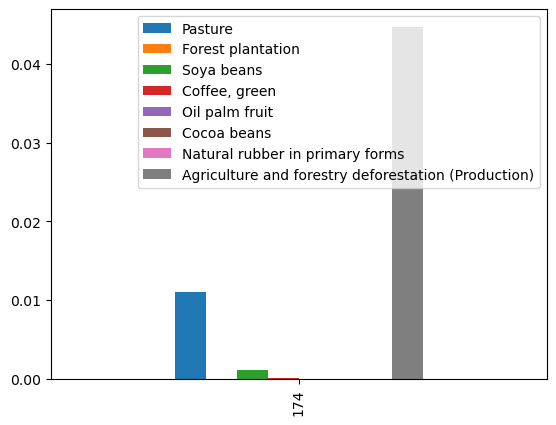

KeyboardInterrupt: Interrupted by user

In [28]:

while True:

    row = df.sample(1)
    print(row.Country.values[0])
    row.plot.bar()
    plt.show()
    _waitforinput = input()

    clear_output(wait=True)
    
    



In [29]:
pd.set_option('display.float_format', lambda x: '%.3f' % x)


In [30]:
def top_n_drivers_for_country(_country, n=10):
    sub_df = grouped_df.loc[grouped_df['Producer country'] == _country].copy(deep=True)


    total_agri_def = country_deforestation_stats.loc[country_deforestation_stats.Country == _country]['Agriculture and forestry deforestation (Production)'].values[0]

    sub_df['Deforestation attribution, unamortized (ha)'] =  sub_df['Deforestation attribution, unamortized (ha)']/total_agri_def




    return sub_df[['Producer country', 'Commodity',
           'Deforestation attribution, unamortized (ha)']]\
        .sort_values('Deforestation attribution, unamortized (ha)', ascending=False ).head(n)
    

In [44]:
__country = np.random.choice(grouped_df['Producer country'].unique())
top_n_drivers_for_country(__country)


,Producer country,Commodity,"Deforestation attribution, unamortized (ha)"
6077,Oman,Bananas,0.424
6084,Oman,"Other vegetables, fresh n.e.c.",0.414
6087,Oman,Wheat,0.064
6080,Oman,Cauliflowers and broccoli,0.027
6086,Oman,Tomatoes,0.026
6081,Oman,Eggplants (aubergines),0.020
6085,Oman,"Pumpkins, squash and gourds",0.013
6079,Oman,Carrots and turnips,0.009
6078,Oman,Cabbages,0.002
6083,Oman,Lemons and limes,0.001


### Comparison with FAOSTAT

In [216]:
faostat_df = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/tmp/faostat_reports.csv')
faostat_df = faostat_df.drop('country_area', axis=1)

<Axes: >

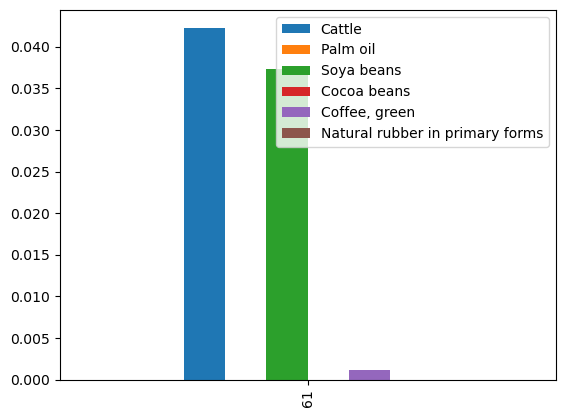

In [237]:
faostat_df.loc[faostat_df.country == 'Zambia'].plot.bar()

In [230]:
cols_without_total_def = ['Cocoa beans', 'Coffee, green', 'Forest plantation', 'Pasture',
       'Oil palm fruit', 'Soya beans', 'Natural rubber in primary forms',
       'Country']

<Axes: >

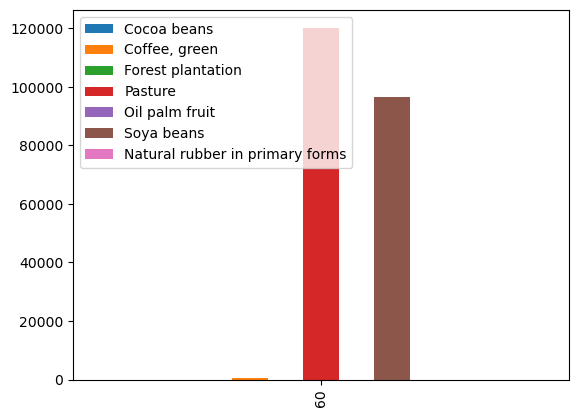

In [238]:
merged_df.loc[merged_df.Country == 'Zambia'][cols_without_total_def].plot.bar()

### DeDuCe subnational statistics Brazil


In [ ]:
xx= pd.read_csv(os.path.join(path, 'Sub-national attribution (Brazil)', 'DeDuCE_Brazil_subnational_Deforestation_attribution_v1.0.0_runID-0-150.csv'))

grouped_xx = xx[['Producer country', 
        'Commodity',
       'Deforestation attribution, unamortized (ha)',
       'Deforestation risk, amortized (ha)']].groupby(['Commodity']).sum().reset_index()


grouped_xx.sort_values('Deforestation attribution, unamortized (ha)', ascending=False )

array(['Ecuador', "Côte d'Ivoire", 'Ghana', 'Colombia', 'Brazil',
       'Viet Nam', 'Indonesia', 'Malaysia', 'Mexico', 'Cuba',
       'Bolivia (Plurinational State of)', 'United States of America',
       'Australia', 'Guatemala', 'Philippines',
       "Lao People's Democratic Republic", 'Peru', 'Guyana', 'India',
       'Democratic Republic of the Congo', 'Papua New Guinea', 'Gabon',
       'Uganda', 'Venezuela (Bolivarian Republic of)', 'Sri Lanka',
       'Myanmar', 'Suriname', 'Ethiopia', 'Liberia', 'Thailand',
       'Bahamas', 'Kenya', 'Dominican Republic',
       'United Republic of Tanzania', 'Timor-Leste', 'Cambodia',
       'Bangladesh', 'Congo', 'Trinidad and Tobago', 'Angola',
       'Central African Republic', 'Fiji', 'Bhutan', 'Panama',
       'Mozambique', 'Madagascar', 'Honduras', 'Sierra Leone', 'Nigeria',
       'Haiti', 'Vanuatu', 'New Caledonia', 'Paraguay', 'Puerto Rico',
       'Cameroon', 'Belize', 'Brunei Darussalam', 'China', 'Guinea',
       'France', 'Nicara